In [130]:
## df mit der pickle datei einlesen

import pandas as pd

df = pd.read_pickle("customer_train_typed.pkl")

In [131]:
## nach Education level Gruppieren

education_groups = df.groupby("education_level")
print(education_groups.size())

education_level
Primary School      308
High School        2017
Graduate          11598
Masters            4361
Phd                 414
dtype: int64


 Anzahl der Personen und Jobsuchenden ermitteln:

Hier passiert Folgendes:

* count: Zählt alle Personen innerhalb der jeweiligen Gruppe.
* sum: Addiert die Boolean-Werte. Bei Boolean-Werten entspricht True einer 1 und False einer 0. Dadurch erhalten wir die Anzahl der wechselwilligen Personen.


In [132]:
education_analysis = education_groups["job_change"].agg(
    total_students="count",
    job_seekers="sum"
)

In [133]:
## Anteil der Jobsuchenden Berechnen:
education_analysis["proportion"] = (
    education_analysis["job_seekers"] / education_analysis["total_students"]
)

In [134]:
## in Prozent umrechnen:
education_analysis["percentage"] = education_analysis["proportion"] * 100

In [135]:
print(education_analysis)

                 total_students  job_seekers  proportion  percentage
education_level                                                     
Primary School              308           41    0.133117   13.311688
High School                2017          394    0.195340   19.533961
Graduate                  11598         3245    0.279790   27.978962
Masters                    4361          935    0.214400   21.440037
Phd                         414           58    0.140097   14.009662


Bei dieser Analyse werden die Missing Values in Education Level ausgeschlossen!

-------Jetzt machen wir ein Barplot Diagram mit Seaborn

In [136]:
## education level als index resetten, da seaborn dann besser arbeitet
education_plot = education_analysis.reset_index()

In [137]:
%pip install seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


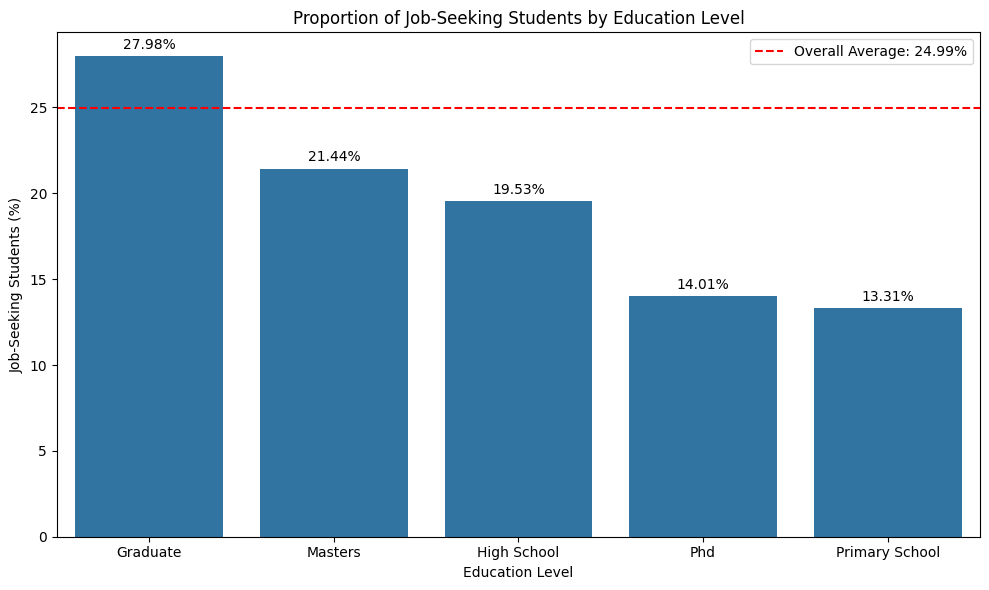

In [138]:
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare and sort data by percentage (descending)
education_plot = education_analysis.reset_index()

education_plot = education_plot[
    education_plot["education_level"].notna()
].sort_values(by="percentage", ascending=False)

# Calculate overall weighted average job-change rate
average_percentage = (
    education_analysis["job_seekers"].sum()
    / education_analysis["total_students"].sum()
    * 100
)

# Create barplot
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=education_plot,
    x="education_level",
    y="percentage",
    order=education_plot["education_level"]
)

# Add percentage labels above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

# Add horizontal line for overall average
plt.axhline(
    y=average_percentage,
    color="red",
    linestyle="--",
    label=f"Overall Average: {average_percentage:.2f}%"
)

# Customize plot
plt.xlabel("Education Level")
plt.ylabel("Job-Seeking Students (%)")
plt.title("Proportion of Job-Seeking Students by Education Level")
plt.legend()
plt.tight_layout()

plt.show()

--------
AQ2
--------

In [139]:
df2 = pd.read_pickle("customer_train_typed.pkl")
df2[["training_hours", "job_change"]].describe()

,training_hours
count,19158.000000
mean,65.366896
std,60.058462
min,1.000000
25%,23.000000
50%,47.000000
75%,88.000000
max,336.000000


Aus den einzelnen ratio Zahlen Kategorien machen:

In [140]:
bins = [0, 25, 50, 75, 100, 125, 150, 175, 200, 250, 300, 400]
labels = ["1-25", "26-50", "51-75", "76-100", "101-125","126-150", "151-175", "176-200", "201-250","251-300","301-400"]

df["hours_group"] = pd.cut(
    df["training_hours"],
    bins=bins,
    labels=labels,
    right=True
)

df["hours_group"].value_counts().sort_index()

hours_group
1-25       5395
26-50      4798
51-75      2984
76-100     2113
101-125    1305
126-150     784
151-175     650
176-200     327
201-250     390
251-300     214
301-400     198
Name: count, dtype: int64

Anteil der Jobsuchenden an der gesamtgruppe der training_hours_completed berechnen

In [141]:
hours_groups = df.groupby("hours_group", observed=True)

hours_analysis = hours_groups["job_change"].agg(
    total_students="count",
    job_seekers="sum"
)

hours_analysis["proportion"] = (
    hours_analysis["job_seekers"] / hours_analysis["total_students"]
)
hours_analysis["percentage"] = hours_analysis["proportion"] * 100

hours_analysis

,total_students,job_seekers,proportion,percentage
hours_group,,,,
1-25,5395,1362,0.252456,25.245598
26-50,4798,1242,0.258858,25.885786
51-75,2984,739,0.247654,24.765416
76-100,2113,512,0.242310,24.230951
101-125,1305,343,0.262835,26.283525
126-150,784,184,0.234694,23.469388
151-175,650,153,0.235385,23.538462
176-200,327,81,0.247706,24.770642
201-250,390,74,0.189744,18.974359


gesamt Anteil der Jobsuchenden berechnen

In [142]:
average_percentage = (
    hours_analysis["job_seekers"].sum()
    / hours_analysis["total_students"].sum()
    * 100
)
average_percentage

np.float64(24.934753105752165)

Visualisierung mit Seaborn

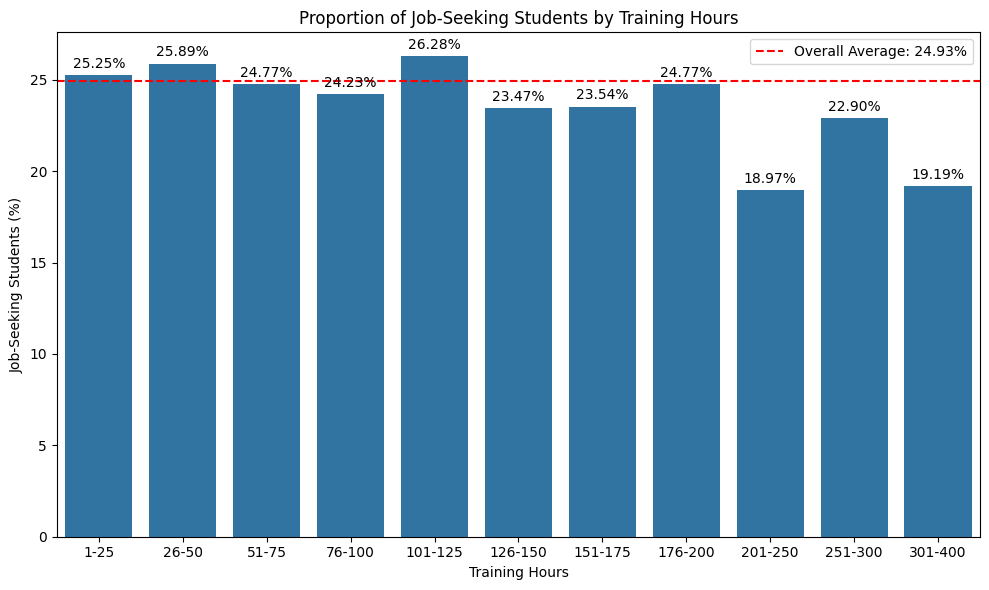

In [143]:
hours_plot = hours_analysis.reset_index()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=hours_plot,
    x="hours_group",
    y="percentage",
    order=labels
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.axhline(
    y=average_percentage,
    color="red",
    linestyle="--",
    label=f"Overall Average: {average_percentage:.2f}%"
)

plt.xlabel("Training Hours")
plt.ylabel("Job-Seeking Students (%)")
plt.title("Proportion of Job-Seeking Students by Training Hours")
plt.legend()
plt.tight_layout()
plt.show()

------
AQ3
------

In [144]:

from scipy.stats import chi2_contingency
import numpy as np

df3 = pd.read_pickle("customer_train_typed.pkl")

##Zeigt dir, wie viele Personen den Job wechseln wollen. Etwa ein Viertel ist True.
df["job_change"].value_counts(normalize=True)

job_change
False    0.750652
True     0.249348
Name: proportion, dtype: float64

In [145]:
# Arbeitskopie erstellen ohne city_xyz und student_id (sind Variablen die nciht in den job change hineinspielen)
# student_id ist nur eine ID, city wird durch city_development_index abgedeckt
data = df3.drop(columns=["student_id", "city"]).copy()

In [146]:
#Fehlende Werte als eigene Kategorie einfügen (??????? Wie damit umgehen ??????)
cat_cols = data.select_dtypes("category").columns

for col in cat_cols:
    data[col] = data[col].cat.add_categories("Unknown").fillna("Unknown")

data.isna().sum()

city_development_index    0
gender                    0
relevant_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
job_change                0
dtype: int64

Aus training hours und city development index kategforien machen

In [147]:
# training_hours: deine Bins
bins = [0, 25, 50, 75, 100, 125, 150, 175, 200, 250, 300, 400]
labels = ["1-25", "26-50", "51-75", "76-100", "101-125", "126-150",
          "151-175", "176-200", "201-250", "251-300", "301-400"]

data["training_hours_group"] = pd.cut(
    data["training_hours"], bins=bins, labels=labels, right=True
)

# city_development_index: Quantil-Bins (gleich große Gruppen)
data["cdi_group"] = pd.qcut(
    data["city_development_index"].astype(float),
    q=5,
    duplicates="drop"
)

print(data["training_hours_group"].value_counts().sort_index())
print(data["cdi_group"].value_counts().sort_index())

training_hours_group
1-25       5395
26-50      4798
51-75      2984
76-100     2113
101-125    1305
126-150     784
151-175     650
176-200     327
201-250     390
251-300     214
301-400     198
Name: count, dtype: int64
cdi_group
(0.447, 0.691]    3869
(0.691, 0.878]    3827
(0.878, 0.92]     8925
(0.92, 0.949]     2537
Name: count, dtype: int64


Beim Index entstehen nur 4 statt 5 Gruppen, weil so viele Personen exakt denselben Wert haben (z. B. 0,920). Das ist wegen duplicates="drop" normal. Die Gruppe (0.878, 0.92] ist dadurch deutlich größer als die anderen, was du bei der Interpretation im Kopf behalten solltest.

Ursporüngliche numerische Spalten entfernen

In [148]:
data = data.drop(columns=["training_hours", "city_development_index"])
data.columns.tolist()

['gender',
 'relevant_experience',
 'enrolled_university',
 'education_level',
 'major_discipline',
 'experience',
 'company_size',
 'company_type',
 'last_new_job',
 'job_change',
 'training_hours_group',
 'cdi_group']

Cramers V berechnen:

In [149]:
def cramers_v(x, y):
    """Bias-korrigiertes Cramér's V zwischen zwei kategorischen Variablen."""
    table = pd.crosstab(x.astype(str), y.astype(str))
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    r, k = table.shape

    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)

    denom = min(k_corr - 1, r_corr - 1)
    return np.sqrt(phi2_corr / denom) if denom > 0 else np.nan

Die Funktion macht eine Kreuztabelle, berechnet den Chi-Quadrat-Wert und normiert ihn auf 0 (kein Zusammenhang) bis 1 (perfekter Zusammenhang). Die Korrektur verhindert, dass Merkmale mit vielen Kategorien automatisch besser abschneiden.

In [150]:
features = [col for col in data.columns if col != "job_change"]

ranking = pd.DataFrame({
    "feature": features,
    "cramers_v": [cramers_v(data[col], data["job_change"]) for col in features]
})

ranking = ranking.sort_values("cramers_v", ascending=False).reset_index(drop=True)
ranking

,feature,cramers_v
0,cdi_group,0.356482
1,company_size,0.245432
2,company_type,0.223137
3,experience,0.188779
4,enrolled_university,0.155048
5,relevant_experience,0.128230
6,education_level,0.092036
7,last_new_job,0.090237
8,gender,0.077269
9,major_discipline,0.055128


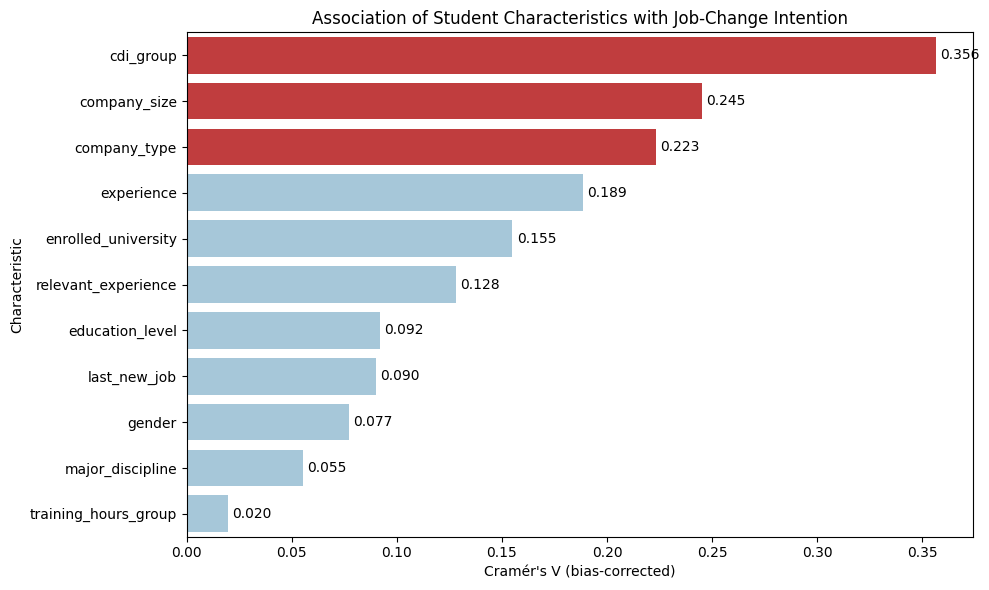

In [151]:
# Top 3 farblich hervorheben
ranking["color"] = ["#d62728" if i < 3 else "#9ecae1" for i in range(len(ranking))]

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=ranking,
    y="feature",
    x="cramers_v",
    hue="feature",
    palette=dict(zip(ranking["feature"], ranking["color"])),
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.xlabel("Cramér's V (bias-corrected)")
plt.ylabel("Characteristic")
plt.title("Association of Student Characteristics with Job-Change Intention")
plt.tight_layout()
plt.show()

Achtung: cdi_grouped = city_development_index als kategorien (siehe berechnung! Kommen wahrscheinlich freagen zu)

------ Heatmap ----

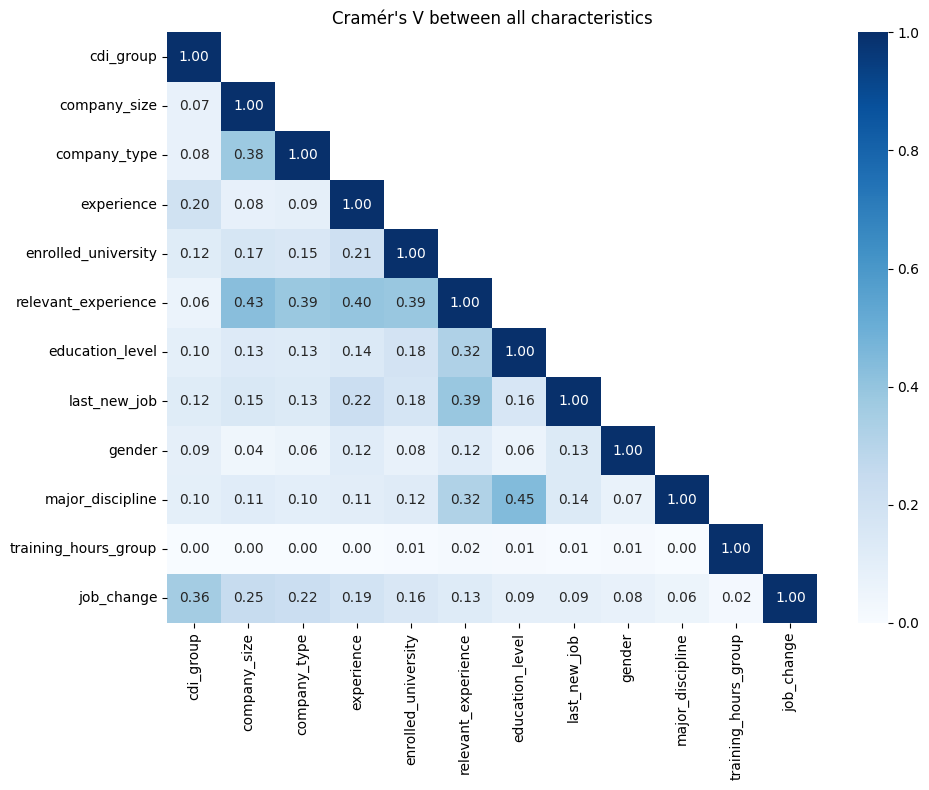

In [152]:
cols = list(ranking["feature"]) + ["job_change"]

matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)
for a in cols:
    for b in cols:
        matrix.loc[a, b] = 1.0 if a == b else cramers_v(data[a], data[b])

mask = np.triu(np.ones_like(matrix, dtype=bool), k=1)  # obere Hälfte ausblenden

plt.figure(figsize=(10, 8))
sns.heatmap(matrix, mask=mask, annot=True, fmt=".2f",
            cmap="Blues", vmin=0, vmax=1)
plt.title("Cramér's V between all characteristics")
plt.tight_layout()
plt.show()

----- Lollipop Plot ------


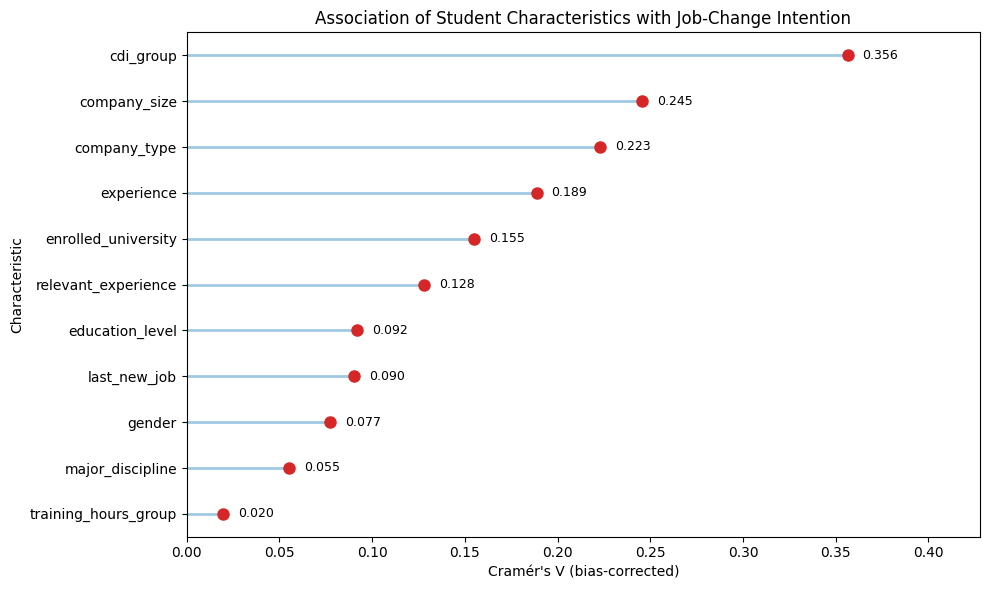

In [153]:
# Ranking umdrehen, damit das stärkste Merkmal oben steht
plot_data = ranking.iloc[::-1]

plt.figure(figsize=(10, 6))

# Linien von 0 bis zum Wert
plt.hlines(
    y=plot_data["feature"],
    xmin=0,
    xmax=plot_data["cramers_v"],
    color="#9ecae1",
    linewidth=2
)

# Punkte am Ende der Linien
plt.plot(
    plot_data["cramers_v"],
    plot_data["feature"],
    "o",
    color="#d62728",
    markersize=8
)

# Werte neben die Punkte schreiben
for value, feature in zip(plot_data["cramers_v"], plot_data["feature"]):
    plt.text(value + 0.008, feature, f"{value:.3f}", va="center", fontsize=9)

plt.xlabel("Cramér's V (bias-corrected)")
plt.ylabel("Characteristic")
plt.title("Association of Student Characteristics with Job-Change Intention")
plt.xlim(0, ranking["cramers_v"].max() * 1.2)
plt.tight_layout()
plt.show()